In [2]:
import warnings
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from perceval.algorithm import Sampler

In [6]:
from qlass.vqe import VQE
from qlass.quantum_chemistry import Hchain_KS_hamiltonian, hamiltonian_matrix
from qlass.vqe.ansatz import Bitstring_initial_states
warnings.filterwarnings('ignore')

In [7]:
#Using KS Hamiltonian
ham, scf_mo_energy, n_orbs = Hchain_KS_hamiltonian(4, 0.784)
print("Printing Hamiltonian",ham)

converged SCF energy = -2.11707366029808
Printing Hamiltonian {'II': 0.15619446357720299, 'ZI': 0.09699617578632595, 'IX': -0.30922602638829955, 'ZX': -0.3267090172827356, 'XI': -0.6668090423686276, 'XX': 0.1101724421113611}


In [8]:
def executor(params, pauli_string):

    processors = Bitstring_initial_states(1, n_orbs, params, pauli_string, cost="e-VQE")
    samplers = [Sampler(p) for p in processors]
    samples = [sampler.samples(10_000) for sampler in samplers]

    return samples

In [9]:
# Initialize the VQE solver
vqe = VQE(
    hamiltonian=ham,
    executor=executor,
    executor_type='sampling',
    num_params=4,  # Number of parameters in the linear entangled ansatz
)

In [10]:
# Run the VQE optimization. Results vary with initial parameters. Normally, random initial paramters are used!
vqe_energy = vqe.run(
    max_iterations=50,
    verbose=True,
    weight_option="weighted",
    cost="e-VQE"
)

Starting VQE optimization using COBYLA optimizer
Number of qubits: 2
Number of parameters: 4
Executor type: sampling
Optimization complete!
Final cost: -0.588756
Final energies: [-0.744342, -0.423758, -0.413768, -0.752451]
Number of iterations: 50


In [11]:
# Calculate the exact energies for comparison
H_matrix = hamiltonian_matrix(ham)
exact_energy = np.sort(np.linalg.eigvals(H_matrix))
print(f"Exact ground state: {exact_energy[0]}, first excited state: {exact_energy[1]}")

Exact ground state: -0.7552045398653, first excited state: -0.4195802545869626


In [12]:
VQE_T = np.add(vqe.energy_collector.energy_data[0], vqe.energy_collector.energy_data[1])
EX_T = exact_energy[0] + exact_energy[1]
error_T = VQE_T - EX_T
error_EA = vqe.energy_collector.energy_data[0] - exact_energy[0]
error_EB = vqe.energy_collector.energy_data[1] - exact_energy[1]

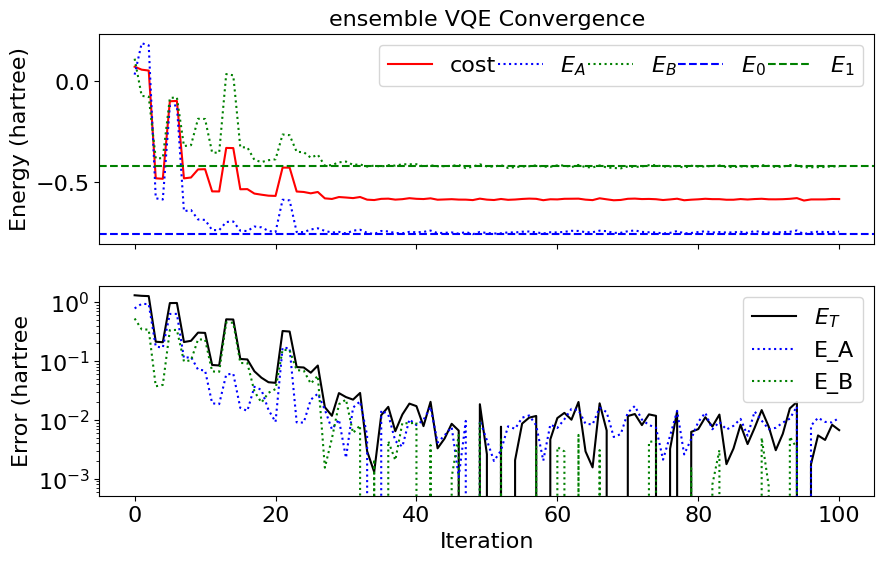

In [13]:
#Results may vary with respect to the initial parameters.
fig, ax = plt.subplots(2,1,figsize=(10, 6))
ax[0].plot(vqe.energy_collector.loss_data, color="red",label='cost')
ax[0].plot(vqe.energy_collector.energy_data[0], ls=":", color="blue", label='$E_A$')
ax[0].plot(vqe.energy_collector.energy_data[1], ls=":", color="green", label='$E_B$')
ax[0].axhline(y=exact_energy[0], color='b', linestyle='--', label='$E_0$')
ax[0].axhline(y=exact_energy[1], color='g', linestyle='--', label='$E_1$')
ax[1].plot(error_T, color='black', ls='-', label = '$E_T$')
ax[1].plot(error_EA, color='b', ls=':', label = 'E_A')
ax[1].plot(error_EB, color='g', ls=':', label = 'E_B')
ax[1].set_yscale('log')
ax[0].set_ylabel('Energy (hartree)', fontsize=16)
ax[1].set_ylabel('Error (hartree', fontsize=16)
ax[1].set_xlabel('Iteration', fontsize=16)
# plt.ylabel('Energy (Hartee)')
ax[0].tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=False)
ax[1].tick_params(axis='both', labelsize=16)
ax[0].tick_params(axis='y', labelsize=16)
ax[1].tick_params(axis='y', labelsize=16)
ax[0].set_title('ensemble VQE Convergence', fontsize=16)
ax[0].legend(fontsize=16, ncol=5, labelspacing=0.02, columnspacing=0.1)
ax[1].legend(fontsize=16)
# plt.tight_layout()
# plt.savefig('vqe_convergence_DFT.png')
plt.show()